In [1]:
from google.colab import files

uploaded = files.upload()

Saving telco_customer_churn.csv to telco_customer_churn.csv


In [2]:
import pandas as pd

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Customers:", len(df))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [4]:
# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values after conversion
print("Missing values after conversion:")
print(df.isnull().sum())

print("\nDataset Shape:", df.shape)

Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Dataset Shape: (7043, 21)


In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing values after cleaning:", df.isnull().sum().sum())

print("Dataset Shape:", df.shape)

Missing values after cleaning: 0
Dataset Shape: (7043, 21)


In [6]:
# Calculate total customers
total_customers = len(df)

# Calculate churned customers
churned_customers = (df["Churn"] == "Yes").sum()

# Calculate churn rate
churn_rate = (churned_customers / total_customers) * 100

# Display results
print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", total_customers - churned_customers)
print("Churn Rate: {:.2f}%".format(churn_rate))

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54%


In [7]:
# Create tenure groups
bins = [0, 12, 24, 36, 48, 60, 72]
labels = [
    "0-12 Months",
    "13-24 Months",
    "25-36 Months",
    "37-48 Months",
    "49-60 Months",
    "61-72 Months"
]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate churn by tenure group
cohort_analysis = df.groupby(
    "TenureGroup", observed=False
).agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
)

cohort_analysis["Churn_Rate"] = (
    cohort_analysis["Churned_Customers"] /
    cohort_analysis["Total_Customers"] * 100
)

print(cohort_analysis.round(2))

              Total_Customers  Churned_Customers  Churn_Rate
TenureGroup                                                 
0-12 Months              2186               1037       47.44
13-24 Months             1024                294       28.71
25-36 Months              832                180       21.63
37-48 Months              762                145       19.03
49-60 Months              832                120       14.42
61-72 Months             1407                 93        6.61


In [8]:
contract_analysis = df.groupby("Contract").agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
)

contract_analysis["Churn_Rate"] = (
    contract_analysis["Churned_Customers"] /
    contract_analysis["Total_Customers"] * 100
)

print(contract_analysis.round(2))

                Total_Customers  Churned_Customers  Churn_Rate
Contract                                                      
Month-to-month             3875               1655       42.71
One year                   1473                166       11.27
Two year                   1695                 48        2.83


In [9]:
payment_analysis = df.groupby("PaymentMethod").agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
)

payment_analysis["Churn_Rate"] = (
    payment_analysis["Churned_Customers"] /
    payment_analysis["Total_Customers"] * 100
)

print(payment_analysis.round(2))

                           Total_Customers  Churned_Customers  Churn_Rate
PaymentMethod                                                            
Bank transfer (automatic)             1544                258       16.71
Credit card (automatic)               1522                232       15.24
Electronic check                      2365               1071       45.29
Mailed check                          1612                308       19.11


In [10]:
high_risk = df[
    (df["InternetService"] == "Fiber optic") &
    (df["TechSupport"] == "No")
]

total_high_risk = len(high_risk)

churned_high_risk = (
    high_risk["Churn"] == "Yes"
).sum()

high_risk_rate = (
    churned_high_risk / total_high_risk * 100
)

print("Fiber Optic Customers without Tech Support")
print("Total Customers:", total_high_risk)
print("Churned Customers:", churned_high_risk)
print("Churn Rate: {:.2f}%".format(high_risk_rate))

Fiber Optic Customers without Tech Support
Total Customers: 2230
Churned Customers: 1101
Churn Rate: 49.37%


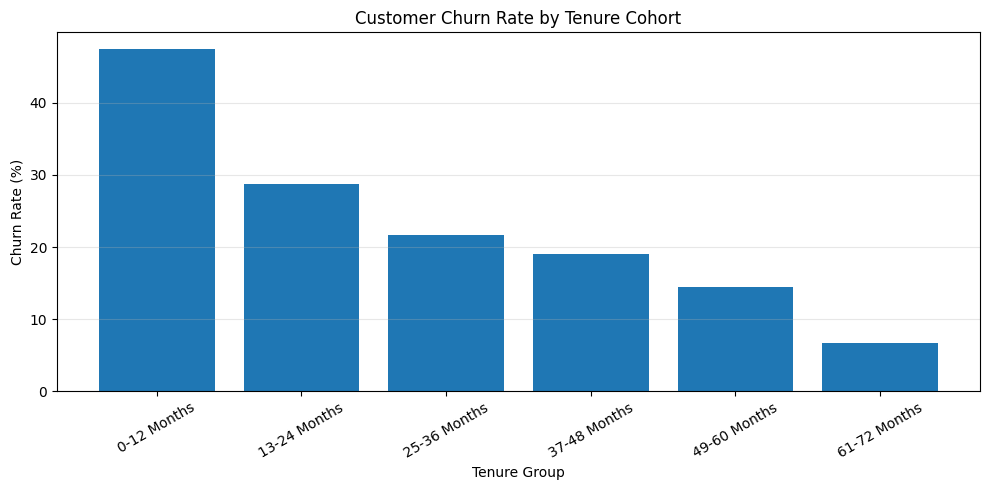

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    cohort_analysis.index.astype(str),
    cohort_analysis["Churn_Rate"]
)

plt.title("Customer Churn Rate by Tenure Cohort")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

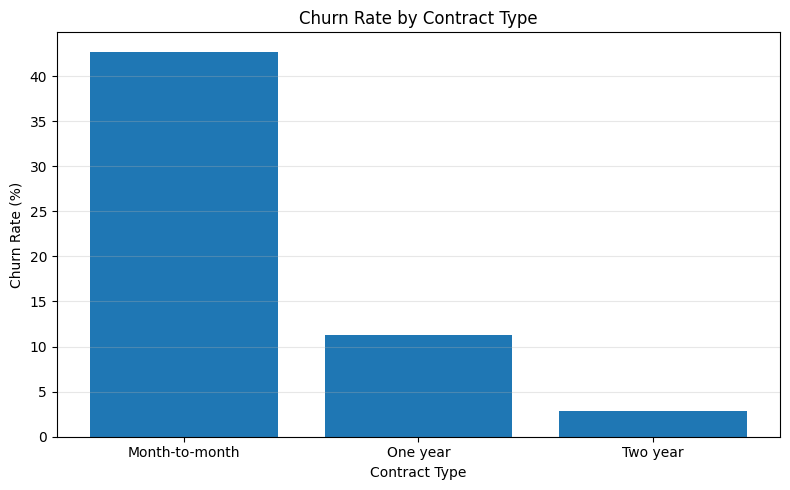

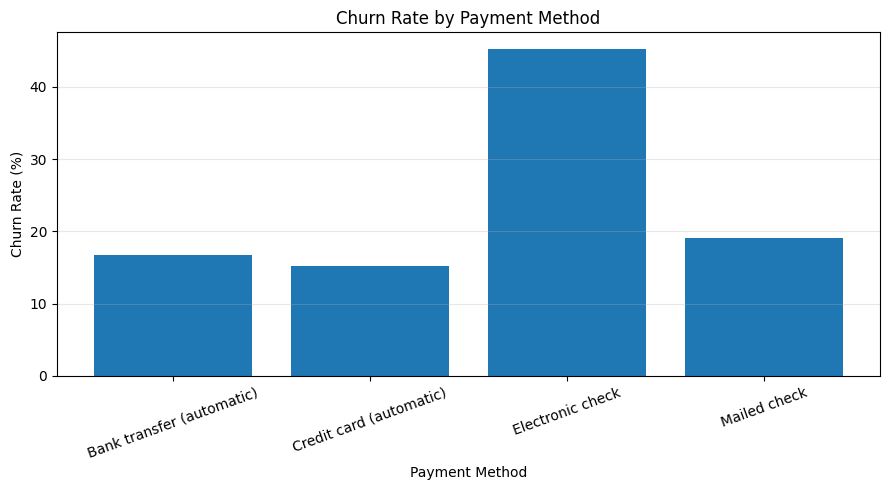

In [12]:
# Contract-wise Churn Chart
plt.figure(figsize=(8, 5))

plt.bar(
    contract_analysis.index,
    contract_analysis["Churn_Rate"]
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Payment Method-wise Churn Chart
plt.figure(figsize=(9, 5))

plt.bar(
    payment_analysis.index,
    payment_analysis["Churn_Rate"]
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
print("=" * 55)
print("CUSTOMER COHORT & CHURN ANALYTICS - FINAL REPORT")
print("=" * 55)

print("\n1. BASELINE CHURN ANALYSIS")
print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", total_customers - churned_customers)
print("Overall Churn Rate: {:.2f}%".format(churn_rate))

print("\n2. TENURE COHORT INSIGHT")
print("Highest Churn Cohort:",
      cohort_analysis["Churn_Rate"].idxmax())
print("Highest Churn Rate: {:.2f}%".format(
    cohort_analysis["Churn_Rate"].max()))

print("\n3. CONTRACT INSIGHT")
print("Highest Churn Contract:",
      contract_analysis["Churn_Rate"].idxmax())
print("Churn Rate: {:.2f}%".format(
    contract_analysis["Churn_Rate"].max()))

print("\n4. PAYMENT METHOD INSIGHT")
print("Highest Churn Payment Method:",
      payment_analysis["Churn_Rate"].idxmax())
print("Churn Rate: {:.2f}%".format(
    payment_analysis["Churn_Rate"].max()))

print("\n5. HIGH-RISK CUSTOMER SEGMENT")
print("Fiber Optic without Tech Support")
print("Customers:", total_high_risk)
print("Churn Rate: {:.2f}%".format(high_risk_rate))

print("\n" + "=" * 55)
print("ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 55)

CUSTOMER COHORT & CHURN ANALYTICS - FINAL REPORT

1. BASELINE CHURN ANALYSIS
Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Overall Churn Rate: 26.54%

2. TENURE COHORT INSIGHT
Highest Churn Cohort: 0-12 Months
Highest Churn Rate: 47.44%

3. CONTRACT INSIGHT
Highest Churn Contract: Month-to-month
Churn Rate: 42.71%

4. PAYMENT METHOD INSIGHT
Highest Churn Payment Method: Electronic check
Churn Rate: 45.29%

5. HIGH-RISK CUSTOMER SEGMENT
Fiber Optic without Tech Support
Customers: 2230
Churn Rate: 49.37%

ANALYSIS COMPLETED SUCCESSFULLY


In [14]:
cohort_analysis.to_csv("tenure_cohort_analysis.csv")
contract_analysis.to_csv("contract_churn_analysis.csv")
payment_analysis.to_csv("payment_method_churn_analysis.csv")
high_risk.to_csv("high_risk_customers.csv", index=False)

summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Churned Customers",
        "Retained Customers",
        "Overall Churn Rate"
    ],
    "Value": [
        total_customers,
        churned_customers,
        total_customers - churned_customers,
        round(churn_rate, 2)
    ]
})

summary.to_csv("churn_summary.csv", index=False)

print("All analysis files saved successfully!")

All analysis files saved successfully!


In [15]:
from google.colab import files

files.download("tenure_cohort_analysis.csv")
files.download("contract_churn_analysis.csv")
files.download("payment_method_churn_analysis.csv")
files.download("high_risk_customers.csv")
files.download("churn_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>